# Preparación del _dataset_ - detección de somnolencia

Para la detección de somnolencia, se ha hecho uso del _dataset_ [UTA-RLDD](https://sites.google.com/view/utarldd/home) ([Ghoddoosian et al., 2019](https://arxiv.org/abs/1904.07312)). En él se encuentran unos 180 vídeos de distintos participantes con distintos estados de atención (de más alerta a más somnoliento). Estos vídeos están etiquetados manualmente por los participantes, en una escala de 0 (alerta) a 10 (cansancio). En este caso, a modo de simplificación (pues no se necesita tanta granularidad), se agrupan todos los valores en 3 categorías:
- Alerta (0)
- Poca atención (5)
- Somnolencia (10)

El propio _dataset_ cuenta con 5 _folds_ que se aprovechan para entrenar y evaluar los modelos mediante el método **5-fold**.

## Índice

1. [Preparación](#1-preparación)
2. [Reducción de los vídeos](#2-reducción-de-los-vídeos)
3. [_Features_ por fotograma](#3-features-por-fotograma)
    - [3.1 Vídeos con pocos fotogramas con cara](#31-vídeos-con-pocos-fotogramas-con-cara)
    - [3.2 Ejemplo - _Eye Aspect Ratio_](#32-ejemplo---eye-aspect-ratio)
    - [3.3 Puntos de la cara utilizados](#33-puntos-de-la-cara-utilizados)
4. [Coste de MediaPipe](#4-coste-de-mediapipe)

## 1. Preparación

Antes de ejecutar este notebook, se deben descargar las 10 carpetas comprimidas que se encuentran en [Google Drive](https://drive.google.com/drive/folders/1d_QwgpMXnLY_FmLYXDn7TLcw0D-svXEl) y descomprimirlas dentro de la carpeta [`videos_dir` en `drowsiness.yaml`](./drowsiness.yaml#L2) (por defecto `../data/uta_rldd`), en una subcarpeta llamada `original/`. Los vídeos reducidos se guardan junto a ella, en `720p20/`.

In [9]:
import sys
from functools import partial
from itertools import count, islice
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

sys.path.insert(0, "..")
from common.benchmark import measure_latency
from common.drowsiness.landmarks import (LEFT_EYE, MOUTH, RIGHT_EYE, extract_video, face_landmarker, frames_table,
                                         pixel_points, read_frames, to_image)
from common.drowsiness.videos import CLASSES, LABELS, PUBLISHABLE, list_videos, reduce_video
from common.experiment import DATA, RESULTS, cached, load_config

cfg = load_config("drowsiness.yaml")
ORIGINAL = Path(cfg.videos_dir) / "original"
REDUCED = Path(cfg.videos_dir) / "720p20"
FRAMES_DIR = DATA / "uta_rldd" / "frames"
RESULTS_DIR = RESULTS / "drowsiness"
FRAMES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

originals = list_videos(ORIGINAL)
display(pd.crosstab(originals.fold, originals.label, margins=True, margins_name="Total")
        .rename(columns={0: "Alerta", 5: "Poca atención", 10: "Somnolencia"})
        .rename_axis(index=None, columns="Fold"))

Fold,Alerta,Poca atención,Somnolencia,Total
1,12,12,12,36
2,12,12,12,36
3,12,12,13,37
4,12,12,12,36
5,12,12,13,37
Total,60,60,62,182


## 2. Reducción de los vídeos

Los vídeos originales cuentan con resoluciones, frecuencias y orientaciones distintas. Para uniformizar los datos de entrada y reducir su tamaño, se realizan las siguientes correcciones:

- Reducir los fotogramas por segundo de cada vídeo a 20 fps como máximo. Esto permite reducir el volumen de datos sin perder calidad de detección.
- Reducir el lado corto de cada vídeo a a 720 px como máximo. Se mantiene a una resolución relativamente elevada, pues los ojos ocupan pocos píxeles, y reducir mucho la resolución podría afectar negativamente a la detección.
- Compresión de los vídeos, haciendo uso de H.264 (CRF 28) y eliminando el audio.

In [10]:
log = pd.DataFrame(Parallel(n_jobs=cfg.compress.workers, prefer="threads")(
    delayed(reduce_video)(video, REDUCED, cfg.compress) for video in originals.itertuples()))
log.to_csv(RESULTS_DIR / "reduccion.csv", index=False)
assert log["verificado"].all(), f"Sin verificar: {log.loc[~log['verificado'], 'video'].tolist()}"
lentos = log.loc[log["fps antes"] < cfg.compress.max_fps, "fps antes"]
print(f"{len(log)} vídeos reducidos y verificados: {log['MB antes'].sum() / 1e3:.1f} GB → {log['MB después'].sum() / 1e3:.1f} GB")
print(f"{len(lentos)} vídeos ya tenían menos de {cfg.compress.max_fps} fps ({lentos.min():.0f}–{lentos.max():.0f} fps) y conservan los suyos")

182 vídeos reducidos y verificados: 120.5 GB → 4.1 GB
22 vídeos ya tenían menos de 20 fps (12–19 fps) y conservan los suyos


## 3. _Features_ por fotograma

Los modelos de detección de somnolencia deben estudiar el comportamiento a lo largo del tiempo. Esto requiere un cierto seguimiento de la secuencia de fotogramas. 

Una primera aproximación podría utilizar una red convolutiva y detectar patrones en los píxeles. No obstante, esto podría ralentizar el entrenamiento, además de que no se cuenta con datos suficientes y variados como para entrenar un modelo de este tipo.

Estos problemas llevan a analizar qué elementos son realmente importantes en la detección del cansancio. Se concluye que analizar las relaciones entre los _landmarks_ podría ser suficiente para esta tarea (por ejemplo, midiendo la apertura de los ojos, o la boca). 

Por esta razón, se reducen los vídeos almacenando los datos clave de sus fotogramas. Se usa el `FaceLandmarker` de `MediaPipe`, guardando los siguientes datos:

- `face`: indica si se ha detectado una cara en el fotograma (1) o no (0).
- `ear_left` y `ear_right`: el _Eye Aspect Ratio_ (EAR) de cada ojo, es decir, la relación entre su altura y su anchura. Cuanto más se acerca este valor a 0, más cerrado está el ojo. Esto permite detectar parpadeos y cierres.
- `mar`: el _Mouth Aspect Ratio_ (MAR), que aplica la misma fórmula a los labios para medir la apertura de la boca. Sirve para detectar bostezos.
- `pitch`, `yaw` y `roll`: orientación de la cabeza en grados y en los distintos ejes, obtenidos a partir de la matriz de transformación de `MediaPipe`. Permiten detectar cabeceos.
- `eyeBlinkLeft`, `eyeBlinkRight`, `eyeSquintLeft`, `eyeSquintRight` y `jawOpen`: _blendshapes_ de `MediaPipe`. Son valores entre 0 y 1 que combinan los distintos _landmarks_ para detectar distintas expresiones faciales. Complementan al EAR y al MAR con una segunda medida de los ojos y la boca.

Los datos de cada vídeo se guardan dentro de `data/uta_rldd/frames/`, ocupando unos 100 MB en total (frente a los 4,1 GB de los vídeos). Junto a ellos se genera un fichero `index.csv` que agrupa la información de todos los vídeos.

In [11]:
reduced = list_videos(REDUCED)
frames = dict(zip(reduced.video, Parallel(n_jobs=cfg.extraction.workers)(
    delayed(cached)(FRAMES_DIR / f"{video.video}.joblib", partial(extract_video, video.path))
    for video in reduced.itertuples())))
tables = {video: frames_table(data) for video, data in frames.items()}

index = reduced.drop(columns="path").assign(
    fps=[data["fps"] for data in frames.values()],
    minutos=[len(table) / data["fps"] / 60 for data, table in zip(frames.values(), tables.values())],
    sin_cara=[1 - table["face"].mean() for table in tables.values()])
index.to_csv(FRAMES_DIR / "index.csv", index=False)
print(f"{len(index)} vídeos, {index['minutos'].sum() / 60:.1f} h, {sum(map(len, tables.values())):,} fotogramas")

182 vídeos, 31.6 h, 2,192,341 fotogramas


### 3.1 Vídeos con pocos fotogramas con cara

Como es lógico, los vídeos necesitan mostrar continuadamente la cara para poder entrenar de forma robusta. Sin embargo, en algunos vídeos la cara no se detecta durante una parte importante de la grabación. Estos son los vídeos más afectados:

In [12]:
display(index.sort_values("sin_cara", ascending=False).head(10).style.format({"sin_cara": "{:.1%}", "minutos": "{:.1f}"}))

,video,fold,participant,label,fps,minutos,sin_cara
147,49_10_2,5,49,10,20.000000,19.5,33.2%
66,23_0,2,23,0,20.000000,9.8,2.9%
67,23_10,2,23,10,20.000000,10.1,1.1%
68,23_5,2,23,5,20.000000,9.6,1.1%
126,42_5,4,42,5,20.000000,10.1,1.0%
11,04_5,1,4,5,20.000000,10.1,0.8%
57,20_0,2,20,0,20.000000,10.9,0.7%
58,20_10,2,20,10,20.000000,12.0,0.6%
59,20_5,2,20,5,20.000000,10.1,0.6%
98,33_10,3,33,10,20.000000,9.3,0.6%


### 3.2 Ejemplo - _Eye Aspect Ratio_

A continuación se muestra un ejemplo de la evolución del _eye aspect ratio_ de un participante en distintos estados de atención. A partir de estas gráficas, se puede estudiar la diferencia en comportamiento en base a los parpadeos.

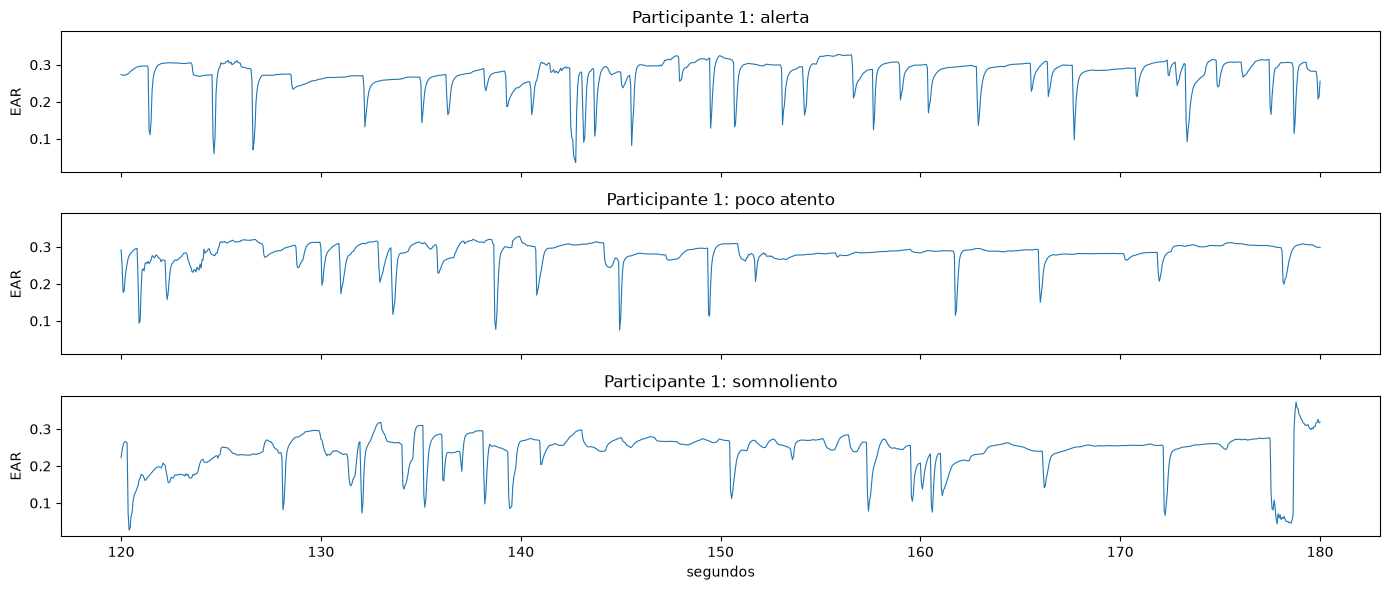

In [13]:
participant = min(PUBLISHABLE & set(index["participant"]))
fig, axes = plt.subplots(3, 1, figsize=(14, 6), sharex=True, sharey=True)
for ax, label, name in zip(axes, LABELS, CLASSES):
    minute = tables[f"{participant:02d}_{label}"].loc[120:180]
    ax.plot(minute[["ear_left", "ear_right"]].mean(axis=1), lw=0.8)
    ax.set(title=f"Participante {participant}: {name}", ylabel="EAR")
axes[-1].set_xlabel("segundos")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ear_ejemplo.png", dpi=120)
plt.show()

### 3.3 Puntos de la cara utilizados

Fotograma de un vídeo, marcando los puntos de los ojos y la boca utilizados para calcular el EAR y el MAR:

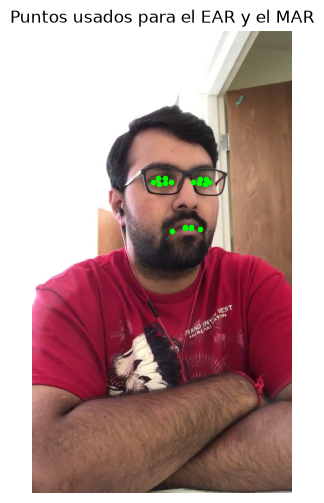

In [14]:
frame = next(read_frames(reduced.set_index("video").loc[f"{participant:02d}_0", "path"], start_ms=30_000))
with face_landmarker() as landmarker:
    landmarks = landmarker.detect_for_video(to_image(frame), 0).face_landmarks[0]
plt.figure(figsize=(5, 6))
plt.imshow(frame)
plt.scatter(*pixel_points(landmarks, LEFT_EYE + RIGHT_EYE + MOUTH, frame.shape).T, s=9, c="lime")
plt.axis("off")
plt.title("Puntos usados para el EAR y el MAR")
plt.show()

## 4. Coste de MediaPipe

Como la demostración se debe ejecutar en tiempo real (20 fps aproximadamente), es de gran importancia analizar el tiempo consumido en la detección de _landmarks_ por FaceLandmarker. En este caso, se observa que se puede utilizar en _realtime_ sin ningún problema:

In [15]:
images = iter([to_image(frame) for frame in islice(read_frames(reduced.path.iloc[0]), cfg.timing.iters + cfg.timing.warmup)])
timestamps = count(step=50)
with face_landmarker() as landmarker:
    latency = measure_latency(lambda: landmarker.detect_for_video(next(images), next(timestamps)),
                              cfg.timing.iters, cfg.timing.warmup)
pd.DataFrame([latency]).to_csv(RESULTS_DIR / "coste_mediapipe.csv", index=False)
print(f"MediaPipe: {latency['mean_ms']:.1f} ms por fotograma (p95 {latency['p95_ms']:.1f} ms)")

MediaPipe: 4.0 ms por fotograma (p95 4.6 ms)
